# TP — Transfert d'apprentissage avec VGG19 et visualisation t-SNE

**Réseaux de Neurones & Deep Learning II · ÉNSP Yaoundé · Groupe 3**

**Objectif.** On utilise VGG19, entraîné sur ImageNet, comme *extracteur de caractéristiques* pour les images de produits Flipkart.
On retire les couches entièrement connectées, on résume chaque image par un vecteur obtenu par *moyenne globale* (global average pooling),
puis on projette ces vecteurs en 2D avec t-SNE. Chaque point du graphe est une image, colorée selon sa catégorie.

**La question posée.** Si les points d'une même couleur se regroupent en blocs séparés, les caractéristiques de VGG19 distinguent bien les catégories :
le modèle est exploitable pour la classification. Si les couleurs sont mélangées, il ne l'est pas, du moins pas tel quel.

Plan : 1. chargement des données · 2. modèle sans couches FC · 3. extraction des caractéristiques · 4. réduction t-SNE · 5. mesures objectives · 6. commentaire.

## 0. Bibliothèques et paramètres

In [1]:
# Installation (une seule fois, dans un terminal) :
#   python -m pip install tensorflow scikit-learn pandas matplotlib pillow openpyxl xlrd
import os, re, glob, ast, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
Image.MAX_IMAGE_PIXELS = None   # une image Flipkart dépasse 89 Mpx : jeu de données de confiance, on lève la limite

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.vgg19 import VGG19, preprocess_input

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
# ---------------------------------------------------------------
# À ADAPTER : chemin du dossier Flipkart sur votre ordinateur
# ---------------------------------------------------------------
DATA_DIR = r"C:\Users\Lenovo\Documents\mes cours\Réseaux de Neurones  Deep Learning II\Dataset+projet+prétraitement+textes+images\Flipkart"

def resoudre_chemin(chemin):
    """Retrouve un dossier même si ses accents sont encodés autrement sur le disque.

    Un dossier extrait d'un zip peut écrire « é » en deux caractères (e + accent combinant) :
    à l'écran c'est identique, mais Windows y voit un autre nom et le chemin « n'existe pas ».
    On compare donc les noms après normalisation Unicode (NFC), dossier par dossier.
    """
    if os.path.isdir(chemin):
        return chemin
    nfc = lambda s: unicodedata.normalize("NFC", s)
    lecteur, reste = os.path.splitdrive(os.path.abspath(chemin))
    courant = lecteur + os.sep
    for partie in [p for p in reste.split(os.sep) if p]:
        candidat = os.path.join(courant, partie)
        if not os.path.isdir(candidat):
            trouves = [n for n in os.listdir(courant) if nfc(n) == nfc(partie)]
            if not trouves:
                return chemin          # vraiment introuvable : on laisse l'erreur se produire plus loin
            candidat = os.path.join(courant, trouves[0])
        courant = candidat
    return courant

# Si le notebook est rangé à côté du dossier Flipkart, on l'utilise directement
if os.path.isdir("Flipkart"):
    DATA_DIR = os.path.abspath("Flipkart")
DATA_DIR = resoudre_chemin(DATA_DIR)
print("Dossier des données :", DATA_DIR, "->", "trouvé" if os.path.isdir(DATA_DIR) else "INTROUVABLE")

WEIGHTS    = "imagenet"   # poids pré-entraînés téléchargés automatiquement (~80 Mo, une seule fois)
IMG_SIZE   = 224          # taille d'entrée attendue par VGG19
BATCH_SIZE = 32
SEED       = 42
OUT_DIR    = "resultats_vgg19"   # figures et caractéristiques sauvegardées ici
os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)
tf.random.set_seed(SEED)

def sauver_figure(nom, **options):
    """Enregistre la figure courante dans OUT_DIR.
    Si le fichier est ouvert dans une visionneuse (ex. l'application Photos), Windows refuse
    de l'écraser (OSError, Errno 22 ou 13) : on enregistre alors sous un autre nom au lieu de planter."""
    chemin = os.path.join(OUT_DIR, nom)
    try:
        plt.savefig(chemin, **options)
    except OSError:
        base, ext = os.path.splitext(chemin)
        chemin = f"{base}_{time.strftime('%H%M%S')}{ext}"
        plt.savefig(chemin, **options)
        print(f"Fichier d'origine verrouillé (ouvert ailleurs ?) : figure enregistrée sous {chemin}")


Dossier des données : C:\Users\Lenovo\Documents\mes cours\Réseaux de Neurones  Deep Learning II\Dataset+projet+prétraitement+textes+images\Flipkart -> trouvé


## 1. Chargement des données

Le jeu Flipkart est fourni sous la forme d'un **fichier de données** (Excel ou CSV, une ligne par produit) et d'un dossier d'images.
La catégorie se lit dans la colonne `product_category_tree`, qui ressemble à
`["Home Furnishing >> Curtains & Accessories >> Curtains >> ..."]` : on garde le **premier niveau** (`Home Furnishing`).

La fonction ci-dessous cherche toute seule le fichier (`.xlsx`, `.xls` ou `.csv`) et le dossier d'images, puis repère :
- la **colonne des images**, celle dont les valeurs correspondent aux noms des fichiers présents dans le dossier ;
- la **colonne des catégories** : `product_category_tree` si elle existe, sinon une colonne dont le nom évoque une catégorie (`categorie`, `category`, `label`, `classe`…).

Si votre dossier est plutôt organisé avec **un sous-dossier par catégorie**, elle le détecte aussi.
Si la détection se trompe, vous pouvez imposer les noms de colonnes avec `COL_IMAGE` et `COL_CATEGORIE`.

In [3]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
COL_IMAGE = None       # ex. "image"                  (None = détection automatique)
COL_CATEGORIE = None   # ex. "product_category_tree"  (None = détection automatique)

def premier_niveau(arbre):
    # '["A >> B >> C"]'  ->  'A'   ;   'Watches'  ->  'Watches'
    try:
        arbre = ast.literal_eval(arbre)[0]
    except Exception:
        arbre = str(arbre).strip('[]"\' ')
    return arbre.split(">>")[0].strip()

def lire_tableau(fichier):
    if fichier.lower().endswith(".csv"):
        return pd.read_csv(fichier)
    return pd.read_excel(fichier)   # .xlsx : openpyxl ; .xls : xlrd

def trouver_colonnes(tab, images):
    col_img = COL_IMAGE
    if col_img is None:
        scores = {c: tab[c].fillna("").astype(str).str.strip().map(lambda v: os.path.basename(v) in images).mean() for c in tab.columns}
        col_img = max(scores, key=scores.get)
        if scores[col_img] == 0:
            return None, None
    col_cat = COL_CATEGORIE
    if col_cat is None:
        noms = {c.lower(): c for c in tab.columns}
        col_cat = noms.get("product_category_tree") or next(
            (c for c in tab.columns if re.search(r"cat[eé]g|label|class|target|famille|type", str(c), re.I) and c != col_img), None)
    return col_img, col_cat

def charger_flipkart(racine):
    if not os.path.isdir(racine):
        raise FileNotFoundError(f"Dossier introuvable : {racine}")
    # Toutes les images présentes, indexées par nom de fichier
    images = {}
    for chemin in glob.glob(os.path.join(racine, "**", "*"), recursive=True):
        if chemin.lower().endswith(IMG_EXT):
            images.setdefault(os.path.basename(chemin), chemin)
    print(f"{len(images)} fichiers image trouvés dans le dossier.")

    # Cas 1 : un fichier Excel ou CSV qui associe chaque image à sa catégorie
    tableaux = [f for ext in ("xlsx", "xls", "csv") for f in glob.glob(os.path.join(racine, "**", f"*.{ext}"), recursive=True)
                if not os.path.basename(f).startswith("~$")]   # ignore les fichiers temporaires d'Excel ouvert
    for fichier in tableaux:
        try:
            tab = lire_tableau(fichier)
        except Exception as e:
            print(f"Lecture impossible de {os.path.basename(fichier)} : {e}")
            continue
        col_img, col_cat = trouver_colonnes(tab, images)
        if col_img is None or col_cat is None:
            continue
        df = pd.DataFrame({"image": tab[col_img].fillna("").astype(str).str.strip().map(os.path.basename),
                           "categorie": tab[col_cat].apply(premier_niveau)})
        if "product_name" in tab:
            df["product_name"] = tab["product_name"]
        df["chemin"] = df["image"].map(images)
        manquantes = df["chemin"].isna().sum()
        if manquantes:
            print(f"Attention : {manquantes} images citées dans le fichier sont absentes du dossier.")
        print(f"Fichier utilisé : {os.path.basename(fichier)} · colonne image = '{col_img}' · colonne catégorie = '{col_cat}'")
        return df.dropna(subset=["chemin"]).reset_index(drop=True)

    # Cas 2 : un sous-dossier par catégorie
    lignes = [{"image": n, "chemin": c, "categorie": os.path.basename(os.path.dirname(c))} for n, c in images.items()]
    if not lignes:
        raise FileNotFoundError("Aucune image trouvée dans ce dossier.")
    print("Pas de fichier Excel/CSV exploitable : la catégorie est lue dans le nom du sous-dossier.")
    return pd.DataFrame(lignes)

df = charger_flipkart(DATA_DIR)
CATEGORIES = sorted(df["categorie"].unique())
print(f"{len(df)} images, {len(CATEGORIES)} catégories")
df["categorie"].value_counts().to_frame("nombre d'images")

1050 fichiers image trouvés dans le dossier.


Fichier utilisé : flipkart_com-ecommerce_sample_1050.csv · colonne image = 'image' · colonne catégorie = 'product_category_tree'
1050 images, 7 catégories


,nombre d'images
categorie,
Home Furnishing,150
Baby Care,150
Watches,150
Home Decor & Festive Needs,150
Kitchen & Dining,150
Beauty and Personal Care,150
Computers,150


Un exemple d'image par catégorie, pour se faire une idée de ce que le réseau va devoir distinguer.

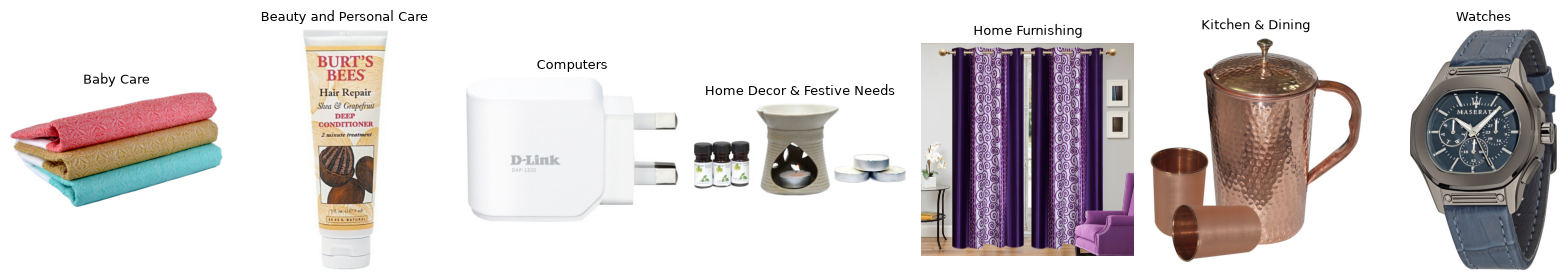

In [4]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(2.3 * len(CATEGORIES), 2.9))
axes = np.atleast_1d(axes)
for ax, cat in zip(axes, CATEGORIES):
    chemin = df.loc[df["categorie"] == cat, "chemin"].iloc[0]
    ax.imshow(keras.utils.load_img(chemin))
    ax.set_title(cat, fontsize=9, wrap=True)
    ax.axis("off")
plt.tight_layout()
sauver_figure("exemples_categories.png", dpi=150)
plt.show()

## 2. VGG19 sans ses couches entièrement connectées

VGG19 se compose de 16 couches de convolution (5 blocs) suivies de 3 couches entièrement connectées (FC) qui servent à classer les 1 000 catégories d'ImageNet.
Ces couches FC sont spécialisées pour ImageNet : on les **supprime** avec `include_top=False`.

À la sortie du dernier bloc convolutif, une image de $224\times224$ est devenue un volume de $7\times7\times512$ : 512 cartes de caractéristiques de $7\times7$.
L'option `pooling="avg"` ajoute une **moyenne globale** (*global average pooling*) qui résume chaque carte par sa moyenne :

$$z_k \;=\; \frac{1}{7\times7}\sum_{i=1}^{7}\sum_{j=1}^{7} A_{i,j,k}, \qquad k = 1,\dots,512.$$

Chaque image est donc décrite par un vecteur de **512 nombres**, qui mesure à quel point chacun des 512 motifs appris sur ImageNet est présent dans l'image.
Les poids sont gelés : on n'entraîne rien, on se contente de lire ce que le réseau « voit ».

In [5]:
extracteur = VGG19(weights=WEIGHTS, include_top=False, pooling="avg",
                   input_shape=(IMG_SIZE, IMG_SIZE, 3))
extracteur.trainable = False
print("Entrée :", extracteur.input_shape, "→ sortie :", extracteur.output_shape)
print(f"Paramètres : {extracteur.count_params():,}".replace(",", " "))
print("Dernières couches :", [c.name for c in extracteur.layers[-4:]])

Entrée : (None, 224, 224, 3) → sortie : (None, 512)
Paramètres : 20 024 384
Dernières couches : ['block5_conv3', 'block5_conv4', 'block5_pool', 'global_average_pooling2d']


## 3. Extraction des caractéristiques

Chaque image est redimensionnée en $224\times224$, convertie en RVB, puis passée par `preprocess_input`, qui applique **exactement** le prétraitement utilisé
lors de l'entraînement de VGG19 (passage en BGR et soustraction de la couleur moyenne d'ImageNet). Oublier cette étape dégrade fortement les caractéristiques, sans erreur visible.

Le résultat est sauvegardé dans `resultats_vgg19/` : si vous relancez le notebook, l'extraction n'est pas refaite.

In [6]:
def lire_image(chemin):
    img = keras.utils.load_img(chemin, target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb")
    return keras.utils.img_to_array(img)

fichier_cache = os.path.join(OUT_DIR, f"caracteristiques_vgg19_{len(df)}.npz")
if os.path.exists(fichier_cache):
    cache = np.load(fichier_cache, allow_pickle=True)
    X, y = cache["X"], cache["y"].astype(str)
    print("Caractéristiques rechargées depuis", fichier_cache)
else:
    debut, morceaux = time.time(), []
    chemins = df["chemin"].tolist()
    for i in range(0, len(chemins), BATCH_SIZE):
        lot = np.stack([lire_image(c) for c in chemins[i:i + BATCH_SIZE]])
        morceaux.append(extracteur.predict(preprocess_input(lot), verbose=0))
        print(f"\r{min(i + BATCH_SIZE, len(chemins))}/{len(chemins)} images", end="")
    X, y = np.vstack(morceaux), df["categorie"].astype(str).to_numpy()
    np.savez_compressed(fichier_cache, X=X, y=y)
    print(f"\nTerminé en {time.time() - debut:.0f} s")

print("Matrice des caractéristiques :", X.shape)

Caractéristiques rechargées depuis resultats_vgg19\caracteristiques_vgg19_1050.npz
Matrice des caractéristiques : (1050, 512)


## 4. Réduction en 2D avec t-SNE

**t-SNE** (*t-distributed Stochastic Neighbor Embedding*) place chaque image sur un plan de façon à ce que deux images **proches dans l'espace à 512 dimensions restent proches en 2D**.
Elle préserve surtout le voisinage local : les groupes qu'on voit sur le graphe sont fiables, mais la distance entre deux groupes éloignés, ou la taille d'un groupe, ne s'interprètent pas.

Deux réglages :
- on applique d'abord une **ACP à 50 composantes**, pratique courante qui retire le bruit et accélère t-SNE ;
- la **perplexité** (30 ici) correspond à peu près au nombre de voisins que t-SNE cherche à respecter pour chaque point.

t-SNE est aléatoire : on fixe `random_state` pour obtenir toujours le même graphe.

In [7]:
n_comp = min(50, X.shape[0] - 1, X.shape[1])
X_pca = PCA(n_components=n_comp, random_state=SEED).fit_transform(X)
perplexite = min(30, (len(X) - 1) / 3)

tsne = TSNE(n_components=2, perplexity=perplexite, init="pca", learning_rate="auto", random_state=SEED)
X_2d = tsne.fit_transform(X_pca)
print("Projection 2D :", X_2d.shape, "· perplexité", perplexite)

Projection 2D : (1050, 2) · perplexité 30


Chaque point est une image ; sa couleur indique sa vraie catégorie. Le nom de chaque catégorie est placé au centre de son nuage.

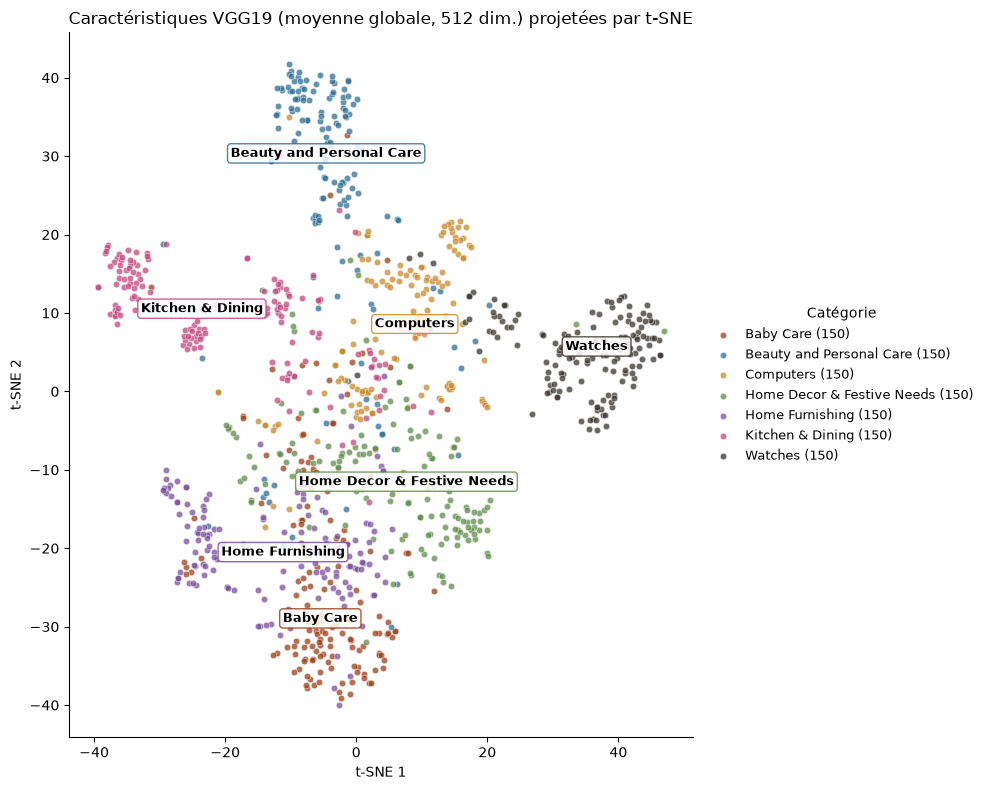

In [8]:
PALETTE = ["#9C3F17", "#2E6F95", "#C98A2B", "#5E8C4A", "#7A4E9C", "#C2477E", "#3A3530",
           "#3C9D9B", "#B5B23C", "#8C6D4F"]
couleurs = {c: PALETTE[i % len(PALETTE)] for i, c in enumerate(CATEGORIES)}

fig, ax = plt.subplots(figsize=(10, 8))
for cat in CATEGORIES:
    m = y == cat
    ax.scatter(X_2d[m, 0], X_2d[m, 1], s=22, alpha=0.75, color=couleurs[cat],
               edgecolors="white", linewidths=0.4, label=f"{cat} ({m.sum()})")
for cat in CATEGORIES:
    cx, cy = np.median(X_2d[y == cat], axis=0)
    ax.text(cx, cy, cat, fontsize=9, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=couleurs[cat], alpha=0.85))
ax.set_title("Caractéristiques VGG19 (moyenne globale, 512 dim.) projetées par t-SNE", fontsize=12)
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9, title="Catégorie")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
sauver_figure("tsne_vgg19_categories.png", dpi=200, bbox_inches="tight")
plt.show()

Pour mieux comprendre les mélanges éventuels, on affiche les images elles-mêmes à leur position t-SNE (un échantillon de 250 images), avec un cadre de la couleur de leur catégorie.

Fichier d'origine verrouillé (ouvert ailleurs ?) : figure enregistrée sous resultats_vgg19\tsne_vgg19_vignettes_111905.png


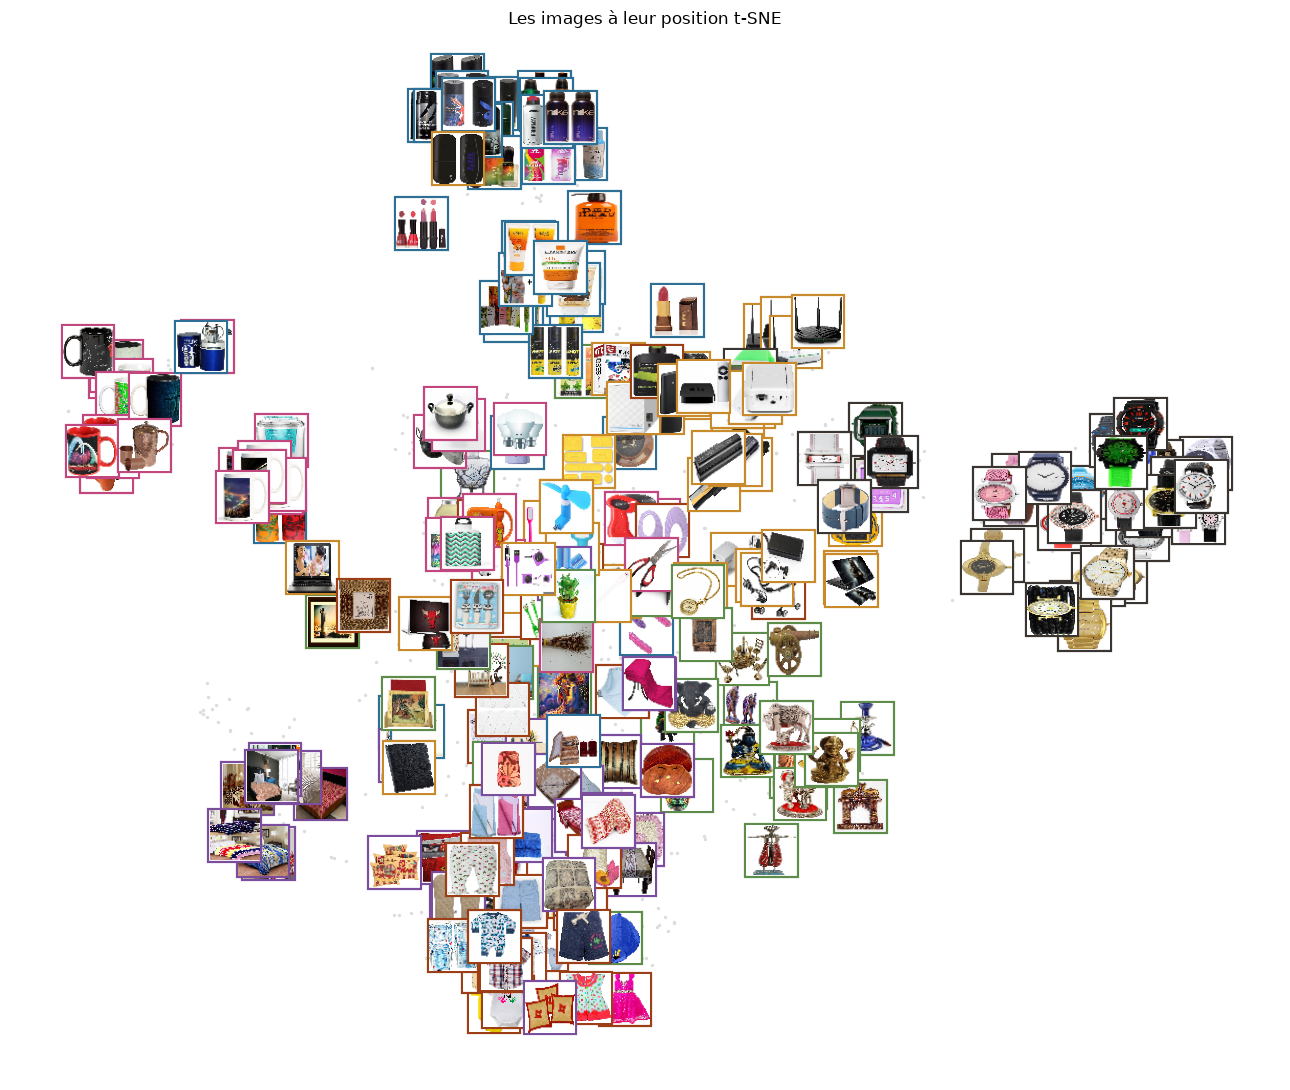

In [9]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

rng = np.random.default_rng(SEED)
idx = rng.choice(len(df), size=min(250, len(df)), replace=False)
fig, ax = plt.subplots(figsize=(13, 11))
ax.scatter(X_2d[:, 0], X_2d[:, 1], s=2, color="#dddddd")
for i in idx:
    vignette = keras.utils.load_img(df.loc[i, "chemin"], target_size=(48, 48))
    ab = AnnotationBbox(OffsetImage(np.asarray(vignette), zoom=0.75), X_2d[i], frameon=True,
                        pad=0.1, bboxprops=dict(edgecolor=couleurs[y[i]], linewidth=1.6))
    ax.add_artist(ab)
ax.set_title("Les images à leur position t-SNE", fontsize=12)
ax.axis("off")
plt.tight_layout()
sauver_figure("tsne_vgg19_vignettes.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Mesurer ce que l'on voit

Un graphe se lit à l'œil, mais quelques chiffres rendent le commentaire plus solide :

- **Pureté du voisinage** : pour chaque image, la part de ses 10 plus proches voisins (sur le graphe 2D) qui appartiennent à la même catégorie. Proche de 100 % : la catégorie forme un bloc. Proche de $1/\text{nombre de catégories}$ : elle est noyée dans les autres.
- **ARI** (*Adjusted Rand Index*) entre les vraies catégories et un regroupement automatique K-means en autant de groupes qu'il y a de catégories. Vaut 1 si les groupes trouvés coïncident parfaitement avec les catégories, environ 0 s'ils sont aléatoires.
- **Score de silhouette** du graphe 2D, entre −1 et 1 : plus il est élevé, plus les catégories sont compactes et séparées.
- **Précision d'un classifieur simple** (régression logistique) entraîné sur les 512 caractéristiques, en validation croisée à 5 plis. C'est le test le plus direct de la question « ce modèle peut-il servir à classer ces images ? ».

In [10]:
k = min(10, len(X_2d) - 1)
_, voisins = NearestNeighbors(n_neighbors=k + 1).fit(X_2d).kneighbors(X_2d)
purete = (y[voisins[:, 1:]] == y[:, None]).mean(axis=1)

clusters = KMeans(n_clusters=len(CATEGORIES), n_init=10, random_state=SEED).fit_predict(X_2d)
ari = adjusted_rand_score(y, clusters)
sil = silhouette_score(X_2d, y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
precision = cross_val_score(clf, X, y, cv=cv, scoring="accuracy")

hasard = 1 / len(CATEGORIES)
print(f"Pureté moyenne du voisinage (10 voisins, 2D) : {purete.mean():.1%}   (hasard ≈ {hasard:.0%})")
print(f"ARI K-means / vraies catégories              : {ari:.3f}")
print(f"Silhouette du graphe 2D                      : {sil:.3f}")
print(f"Précision régression logistique (512 dim.)   : {precision.mean():.1%} ± {precision.std():.1%}")

tableau = (pd.DataFrame({"categorie": y, "purete": purete})
             .groupby("categorie")["purete"].mean().sort_values(ascending=False)
             .to_frame("pureté du voisinage"))
tableau.style.format("{:.1%}")

Pureté moyenne du voisinage (10 voisins, 2D) : 74.6%   (hasard ≈ 14%)
ARI K-means / vraies catégories              : 0.482
Silhouette du graphe 2D                      : 0.217
Précision régression logistique (512 dim.)   : 82.3% ± 2.9%


,pureté du voisinage
categorie,
Watches,94.4%
Kitchen & Dining,82.9%
Computers,74.7%
Beauty and Personal Care,72.9%
Home Decor & Festive Needs,69.0%
Home Furnishing,68.1%
Baby Care,60.2%


Le tableau croisé montre, pour chaque catégorie, dans quels groupes K-means ses images sont tombées. Une catégorie bien séparée se concentre dans une seule colonne ; une catégorie mélangée s'étale sur plusieurs.

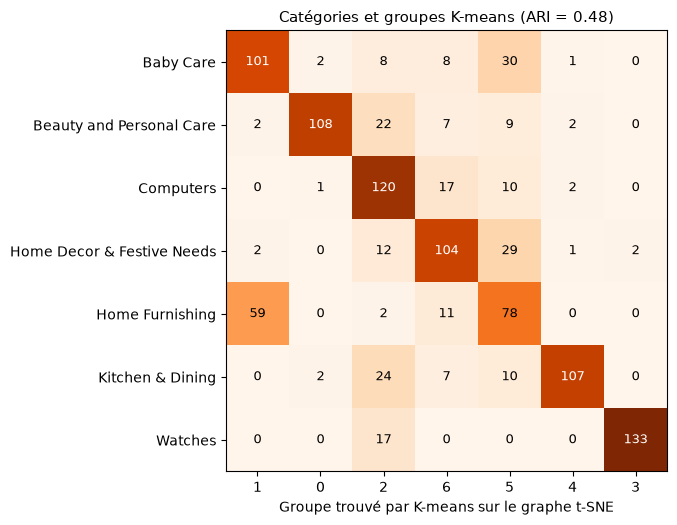

In [11]:
croise = pd.crosstab(pd.Series(y, name="Vraie catégorie"), pd.Series(clusters, name="Groupe K-means"))
croise = croise[croise.idxmax(axis=0).map({c: i for i, c in enumerate(CATEGORIES)}).sort_values().index]

fig, ax = plt.subplots(figsize=(1.0 * len(CATEGORIES) + 3, 0.55 * len(CATEGORIES) + 1.5))
im = ax.imshow(croise.values, cmap="Oranges")
ax.set_xticks(range(croise.shape[1]), croise.columns)
ax.set_yticks(range(croise.shape[0]), croise.index)
for i in range(croise.shape[0]):
    for j in range(croise.shape[1]):
        v = croise.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=9,
                color="white" if v > croise.values.max() * 0.6 else "black")
ax.set_xlabel("Groupe trouvé par K-means sur le graphe t-SNE")
ax.set_title(f"Catégories et groupes K-means (ARI = {ari:.2f})", fontsize=11)
plt.tight_layout()
sauver_figure("kmeans_vs_categories.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Commentaire

*À rédiger après avoir regardé le graphe t-SNE et les mesures ci-dessus. La grille suivante aide à structurer l'analyse.*

**Lecture du graphe**
1. Combien de catégories forment un bloc net, d'une seule couleur ? Lesquelles ?
2. Quelles catégories se mélangent, et avec lesquelles ? Les vignettes expliquent-elles pourquoi (produits visuellement proches, photos sur fond blanc, objets de même forme) ?
3. Y a-t-il des points isolés au milieu d'une autre couleur ? Regarder les images correspondantes : erreur d'étiquette, photo atypique, produit ambigu ?

**Lecture des chiffres**
- Pureté du voisinage nettement au-dessus du hasard, ARI élevé et bonne précision du classifieur : les caractéristiques de VGG19 séparent bien les catégories.
- Valeurs moyennes : séparation partielle. Certaines catégories sont reconnues, d'autres se confondent.
- Valeurs proches du hasard : les caractéristiques ne suffisent pas.

**Conclusion à formuler**
- Le modèle VGG19, sans ses couches FC, peut-il servir à classer ces produits ? Sous quelle forme : tel quel, avec un classifieur ajouté par-dessus, ou après un ajustement fin des derniers blocs ?
- Une limite à garder en tête : t-SNE ne conserve que le voisinage local. Un mélange en 2D ne prouve pas que les classes sont inséparables en 512 dimensions ; c'est pour cela que la précision du classifieur est un complément utile.

**Notre commentaire** (résultats obtenus avec `SEED = 42`, 1 050 images, 7 catégories de 150 images)

**Lecture du graphe.**
- Trois catégories forment des blocs nets, presque d'une seule couleur : **Watches** (à droite, pureté du voisinage 94 %), **Beauty and Personal Care** (en haut) et **Kitchen & Dining** (à gauche, 83 %). Ce sont des produits à la forme très caractéristique : cadran rond et bracelet pour les montres, flacons et tubes pour la beauté, vaisselle et ustensiles pour la cuisine.
- **Computers** forme un groupe assez net (75 %), mais coupé en plusieurs morceaux : les accessoires (souris, claviers, clés USB, câbles) ne se ressemblent pas entre eux.
- Le bas du graphe est mélangé : **Home Furnishing**, **Baby Care** et **Home Decor & Festive Needs** se recouvrent (pureté 60 à 69 %). La confusion principale est entre Baby Care et Home Furnishing. En regardant les images mal placées, on comprend pourquoi : la catégorie Baby Care de Flipkart contient beaucoup de **serviettes de bain** en coton (« Cotton Bath Towel », « Face Towel Set »), qui ressemblent exactement aux housses de coussin, draps et linge de cuisine de Home Furnishing : du textile plié, photographié sur fond blanc. Le réseau n'a aucun moyen visuel de deviner que la serviette est rangée dans « bébé ». Home Decor regroupe des objets très variés (statuettes, cadres muraux, objets décoratifs), ce qui l'éparpille.
- Les points isolés au milieu d'une autre couleur sont surtout des produits **ambigus par leur catégorie**, plutôt que des erreurs du réseau : par exemple quelques montres numériques, proches visuellement des accessoires électroniques de Computers.

**Lecture des chiffres.**
- Pureté moyenne du voisinage : **74,6 %**, contre 14 % au hasard (1/7) : les voisins d'une image sont en majorité de sa catégorie.
- ARI K-means : **0,48**, séparation partielle. Le tableau croisé le confirme : Watches, Computers, Beauty et Kitchen tombent chacune dans un groupe dominant, tandis que Home Furnishing est coupé en deux groupes partagés avec Baby Care et Home Decor.
- Silhouette 2D : **0,22**, positive mais faible : les groupes existent, mais ils se touchent.
- Régression logistique sur les 512 caractéristiques : **82,3 % ± 2,9 %** de précision en validation croisée, soit environ 6 fois mieux que le hasard. Par catégorie (score F1) : Watches 0,95, Kitchen & Dining 0,88, Computers 0,86, Beauty 0,83, Home Decor 0,76, Home Furnishing 0,76, Baby Care 0,71. Les 21 Baby Care classés Home Furnishing (et réciproquement 21) sont la confusion la plus fréquente.

**Conclusion.**
Oui, VGG19 sans ses couches entièrement connectées fournit des caractéristiques exploitables pour classer ces produits, **mais pas tel quel** : il faut ajouter un classifieur par-dessus. Un simple classifieur linéaire atteint déjà 82 %, sans aucun entraînement du réseau. La séparation est excellente pour les catégories définies par la forme de l'objet (montres, cuisine, beauté, informatique) et insuffisante pour les catégories définies par l'usage plutôt que par l'apparence (Baby Care contre Home Furnishing). Pour aller plus loin, on peut ajuster finement (fine-tuning) les derniers blocs convolutifs (`block5`) sur ces images, ou combiner l'image avec le texte de la description du produit, qui peut lever une partie de ces ambiguïtés (mots comme « Baby », « Kids » ou « Towel » dans le nom du produit).

La précision de 82 % en 512 dimensions, supérieure à ce que suggère le graphe, illustre la limite de t-SNE : un mélange en 2D ne prouve pas que les classes soient inséparables dans l'espace d'origine.